# SVD and PCA: a geometric exploration

Related video: [Singular Value Decomposition (the SVD)](https://www.youtube.com/watch?v=mBcLRGuAFUk)

Explore how a matrix transforms space, then discover why PCA can be computed using SVD.

**Setup:** Run all cells in order. If dependencies are missing, run `%pip install numpy matplotlib ipywidgets` in a notebook cell and restart the kernel. Use a Jupyter frontend with widget support. In PyCharm, if widgets are unavailable, call the plotting functions directly with numerical arguments.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)

## 1. Rotation, reflection and scaling

For column vectors, $A=U\Sigma V^T$ acts from right to left: first $V^T$, then $\Sigma$, then $U$.

$$R(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix},\qquad \Sigma=\begin{bmatrix}\sigma_1&0\\0&\sigma_2\end{bmatrix}$$

Orthogonal transformations preserve lengths and angles; they may include reflections. Singular values are non-negative and conventionally sorted. A zero singular value collapses a dimension. The coloured arrows track two original basis vectors, while the black dashed lines in the final panel mark the principal output directions.

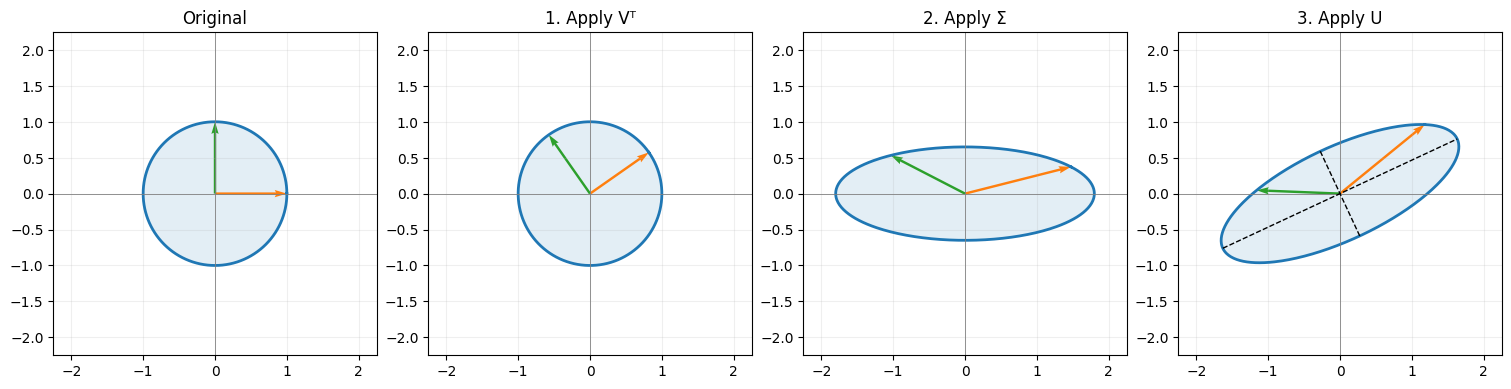

Vᵀ =
 [[ 0.8192 -0.5736]
 [ 0.5736  0.8192]] 
Σ =
 [[1.8  0.  ]
 [0.   0.65]] 
U =
 [[ 0.9063 -0.4226]
 [ 0.4226  0.9063]] 
A =
 [[ 1.1788 -1.1607]
 [ 0.961   0.0462]]
UᵀU = I: True
VVᵀ = I: True
NumPy singular values: [1.8  0.65]
det(U): 1.0


In [8]:
def rotation(degrees):
    theta = np.deg2rad(degrees)
    return np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta),  np.cos(theta)]])


def explore_svd(first_angle=35, second_angle=25, sigma1=1.8, sigma2=0.65, reflect=False):
    Vt = rotation(first_angle)
    U = rotation(second_angle) @ np.diag([1, -1 if reflect else 1])
    s = np.sort([sigma1, sigma2])[::-1]
    S = np.diag(s)
    A = U @ S @ Vt
    t = np.linspace(0, 2*np.pi, 361)
    circle = np.vstack([np.cos(t), np.sin(t)])
    transforms = [np.eye(2), Vt, S @ Vt, A]
    fig, axes = plt.subplots(1, 4, figsize=(15, 4), constrained_layout=True)
    lim = max(1, *s) * 1.25
    for ax, M, title in zip(axes, transforms, ['Original', '1. Apply Vᵀ', '2. Apply Σ', '3. Apply U']):
        p = M @ circle
        ax.plot(*p, color='tab:blue', lw=2)
        ax.fill(*p, alpha=.12)
        for i, colour in enumerate(['tab:orange', 'tab:green']):
            ax.quiver(0, 0, *M[:, i], angles='xy', scale_units='xy', scale=1, color=colour)
        ax.axhline(0, color='grey', lw=.6); ax.axvline(0, color='grey', lw=.6)
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=title, aspect='equal')
        ax.grid(alpha=.2)
    for i in range(2):
        d = U[:, i] * s[i]
        axes[-1].plot([-d[0], d[0]], [-d[1], d[1]], 'k--', lw=1)
    plt.show()
    print('Vᵀ =\n', Vt, '\nΣ =\n', S, '\nU =\n', U, '\nA =\n', A)
    print('UᵀU = I:', np.allclose(U.T @ U, np.eye(2)))
    print('VVᵀ = I:', np.allclose(Vt.T @ Vt, np.eye(2)))
    print('NumPy singular values:', np.linalg.svd(A, compute_uv=False))
    print('det(U):', round(np.linalg.det(U), 4))

explore_svd()

In [9]:
def angle_control(value, description):
    return widgets.IntSlider(value=value, min=-180, max=180, description=description, continuous_update=False)

def scale_control(value, description):
    return widgets.FloatSlider(value=value, min=0, max=3, step=.05, description=description, continuous_update=False)

widgets.interact(explore_svd,
    first_angle=angle_control(35, 'Vᵀ angle'),
    second_angle=angle_control(25, 'U angle'),
    sigma1=scale_control(1.8, 'Scale 1'), sigma2=scale_control(.65, 'Scale 2'),
    reflect=False);

interactive(children=(IntSlider(value=35, continuous_update=False, description='Vᵀ angle', max=180, min=-180),…

Try setting both scales to 1, then one to zero. Toggle reflection and check the determinant. The controls sort the two scale values before constructing $\Sigma$. Rotating an unmarked circle is invisible, which is why we track the coloured basis vectors.

## 2. PCA from covariance versus SVD

For a centred data matrix $X_c\in\mathbb R^{n\times p}$, rows are samples and columns are features. Its sample covariance is

$$C=\frac{X_c^T X_c}{n-1}.$$

Substituting the thin SVD $X_c=U\Sigma V^T$ gives

$$C=V\frac{\Sigma^2}{n-1}V^T$$

where $\Sigma=\operatorname{diag}(\sigma_i)$ for this example ($n\ge p$). Consequently, the principal directions are columns of $V$, the eigenvalues are $\lambda_i=\sigma_i^2/(n-1)$ and the PCA scores are $X_cV=U\Sigma$. The explained variance ratio is $\lambda_i/\sum_j\lambda_j$.

**Important distinction:** for a data matrix, $U$ lives in sample space, not the original two-dimensional feature space. The earlier square-matrix rotation example is geometric intuition, not a literal pair of 2D rotations for rectangular data.

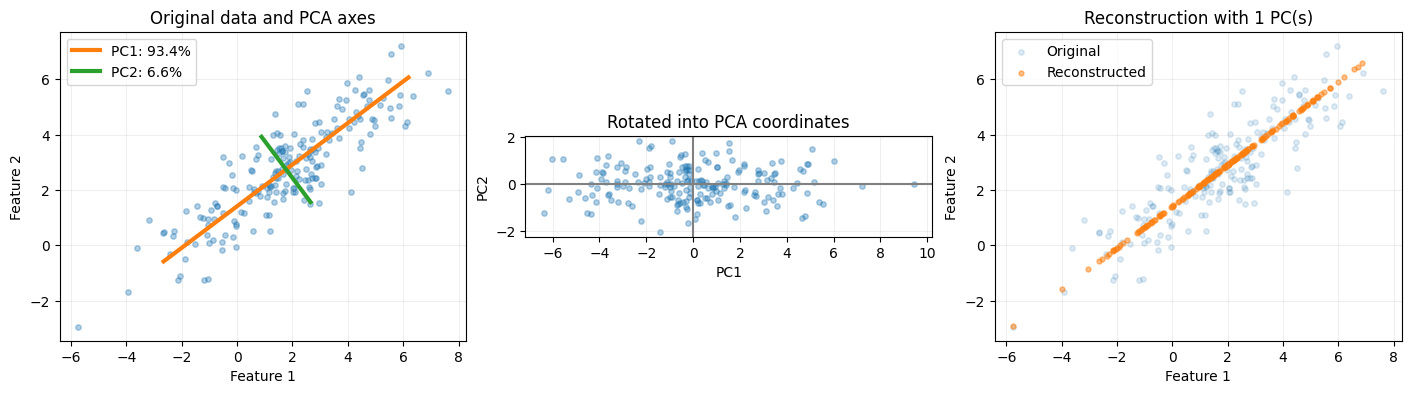

Shapes: Xc (200, 2) U (200, 2) Σ (2, 2) Vᵀ (2, 2)
Covariance matrix:
 [[5.0905 3.416 ]
 [3.416  3.1103]]
Eigenvalues: [7.657  0.5438] 
SVD-derived eigenvalues: [7.657  0.5438]
PCA eigenvectors (sign aligned):
 [[-0.7995 -0.6007]
 [-0.6007  0.7995]] 
Right singular vectors:
 [[-0.7995 -0.6007]
 [-0.6007  0.7995]]
Explained variance ratios: [0.9337 0.0663]
Mean squared reconstruction error: 0.2705534646231082
All decomposition checks passed.


In [10]:
def explore_pca(angle=35, spread1=3.0, spread2=0.8, components=1):
    rng = np.random.default_rng(7)
    X = rng.normal(size=(200, 2)) @ np.diag([spread1, spread2]) @ rotation(angle).T + [2, 3]
    mean = X.mean(axis=0)
    Xc = X - mean
    C = Xc.T @ Xc / (len(X)-1)
    eigenvalues, eigenvectors = np.linalg.eigh(C)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    V = Vt.T
    # Align eigenvector signs for comparison; either sign is mathematically valid.
    signs = np.where(np.sum(eigenvectors * V, axis=0) < 0, -1, 1)
    eigenvectors = eigenvectors * signs
    variances = s**2 / (len(X)-1)
    ratio = variances / variances.sum()
    scores = Xc @ V
    reconstructed = scores[:, :components] @ V[:, :components].T + mean
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
    axes[0].scatter(*X.T, alpha=.35, s=15)
    for i, colour in enumerate(['tab:orange', 'tab:green']):
        d = V[:, i] * 2 * np.sqrt(variances[i])
        axes[0].plot(*np.vstack([mean-d, mean+d]).T, color=colour, lw=3, label=f'PC{i+1}: {ratio[i]:.1%}')
    axes[0].legend(); axes[0].set_title('Original data and PCA axes')
    axes[1].scatter(*scores.T, alpha=.35, s=15)
    axes[1].axhline(0, color='grey'); axes[1].axvline(0, color='grey')
    axes[1].set(title='Rotated into PCA coordinates', xlabel='PC1', ylabel='PC2')
    axes[2].scatter(*X.T, alpha=.15, s=15, label='Original')
    axes[2].scatter(*reconstructed.T, alpha=.5, s=13, label='Reconstructed')
    axes[2].set_title(f'Reconstruction with {components} PC(s)'); axes[2].legend()
    for ax in axes:
        ax.set_aspect('equal', adjustable='box'); ax.grid(alpha=.2)
    axes[0].set(xlabel='Feature 1', ylabel='Feature 2')
    axes[2].set(xlim=axes[0].get_xlim(), ylim=axes[0].get_ylim(), xlabel='Feature 1', ylabel='Feature 2')
    plt.show()
    print('Shapes: Xc', Xc.shape, 'U', U.shape, 'Σ', np.diag(s).shape, 'Vᵀ', Vt.shape)
    print('Covariance matrix:\n', C)
    print('Eigenvalues:', eigenvalues, '\nSVD-derived eigenvalues:', variances)
    print('PCA eigenvectors (sign aligned):\n', eigenvectors, '\nRight singular vectors:\n', V)
    print('Explained variance ratios:', ratio)
    print('Mean squared reconstruction error:', np.mean((X-reconstructed)**2))
    assert np.allclose(eigenvalues, variances)
    assert np.allclose(Xc, U @ np.diag(s) @ Vt)
    assert np.allclose(scores, U * s)
    assert np.allclose(C, V @ np.diag(variances) @ V.T)
    print('All decomposition checks passed.')

explore_pca()

In [11]:
widgets.interact(explore_pca,
    angle=angle_control(35, 'Data angle'),
    spread1=widgets.FloatSlider(value=3, min=.1, max=5, step=.1, description='Spread 1', continuous_update=False),
    spread2=widgets.FloatSlider(value=.8, min=.1, max=5, step=.1, description='Spread 2', continuous_update=False),
    components=widgets.IntSlider(value=1, min=1, max=2, description='PCs'));

interactive(children=(IntSlider(value=35, continuous_update=False, description='Data angle', max=180, min=-180…

## 3. Experiments and conclusions

1. Change only the data angle. The principal directions rotate, but the eigenvalues and explained variance ratios remain unchanged (up to floating-point precision).
2. Make one spread much larger than the other. PC1 captures most of the variance, and one-component reconstruction becomes more accurate relative to total variance.
3. Set both spreads equal. The sample covariance is approximately isotropic, so the principal directions have less structural meaning. For exactly repeated eigenvalues the basis inside that eigenspace is not unique.
4. Switch from one PC to two. Reconstruction error becomes approximately zero.

PCA uses SVD on centred data to find orthogonal feature-space directions ordered by variance. SVD itself does not require centring. If features have incompatible units, consider standardising before PCA; this example deliberately uses comparable feature units.